# Features and zero-shot baseline

Run `python -m src.features.extract` and `python -m src.models.zero_shot` first.

In [1]:
import sys

sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd
import torch
from PIL import Image
from torchvision import transforms as T

from src.data.prepare import OUT_DIR
from src.features.extract import FEATURES_DIR, RAW_DIR, pad_square
from src.models.zero_shot import RESULTS_DIR, accuracy, lookup

## Preprocessing

CLIP's default preprocessing resizes the short side to 224 and center-crops, which cuts off the sides of wide charts (axis labels, first and last bars). We pad every chart to a white square first.

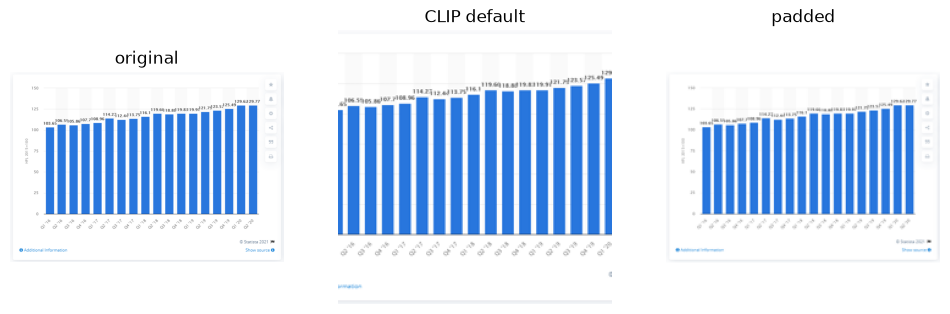

In [2]:
resize_crop = T.Compose([T.Resize(224, interpolation=T.InterpolationMode.BICUBIC), T.CenterCrop(224)])

test = pd.read_csv(OUT_DIR / "test.csv")
image = Image.open(RAW_DIR / test[test.source == "chartqa"].image.iloc[0]).convert("RGB")

views = {"original": image, "CLIP default": resize_crop(image), "padded": resize_crop(pad_square(image))}
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (title, view) in zip(axes, views.items()):
    ax.imshow(view)
    ax.set_title(title)
    ax.axis("off")

Padding keeps the whole chart, but at 224×224 small text such as value labels becomes hard to read. Errors on value lookups may partly come from this resolution limit (an encoding bottleneck), not only from aggregation.

The model is loaded as `ViT-B-16-quickgelu`: the OpenAI weights were trained with QuickGELU, while the plain `ViT-B-16` config uses GELU.

## Features

Per chart: the global embedding (512) and the 196 patch tokens (768, after `ln_post`, before the projection). Per statement: the text embedding (512). Stored in fp16.

In [3]:
images = torch.load(FEATURES_DIR / "images.pt")
texts = torch.load(FEATURES_DIR / "texts.pt")

print("charts:", len(images["paths"]), tuple(images["global"].shape), tuple(images["patches"].shape))
print("statements:", len(texts["statements"]), tuple(texts["emb"].shape))

charts: 9000 (9000, 512) (9000, 196, 768)
statements: 82693 (82693, 512)


## Zero-shot CLIP

Pick the statement with the higher cosine similarity to the chart's global embedding. No training.

In [4]:
pd.DataFrame({split: accuracy(pd.read_csv(RESULTS_DIR / f"zero_shot_{split}.csv")) for split in ["val", "test"]})

,val,test
all,52.8,52.9
chartqa,51.8,51.5
dvqa,56.7,58.0
figureqa,50.0,49.3
comparison,51.9,51.5
lookup,53.5,53.2
other,54.8,57.7


Close to chance overall. FigureQA is at chance: its correct and incorrect statements differ only by a negation ("is" vs "is not").

## Sanity check

Is the near-chance result a pipeline bug? We replace the incorrect statement with the correct statement of another chart from the same source. If features and indices are right, CLIP should win this easier task.

In [5]:
df = test.copy()
df["correct"] = df.option_0.where(df.label == 0, df.option_1)
other = df.groupby("source")[["image", "correct"]].transform(lambda s: s.sample(frac=1, random_state=0).to_numpy())
df = df[other.image != df.image].assign(other=other.correct)

image_emb = lookup(images["global"], images["paths"], df.image)
sim_correct = (image_emb * lookup(texts["emb"], texts["statements"], df.correct)).sum(-1)
sim_other = (image_emb * lookup(texts["emb"], texts["statements"], df.other)).sum(-1)
df["win"] = (sim_correct > sim_other).numpy()

print(f"all: {df.win.mean():.1%}")
df.groupby("source").win.mean().mul(100).round(1)

all: 69.5%


source
chartqa     67.9
dvqa        73.6
figureqa    67.1
Name: win, dtype: float64

## Takeaways

- CLIP knows what a chart is about (it beats statements from other charts) but not its details: values, comparisons and negations are at chance.
- This matches the motivation of the project: the information is local to chart regions and the global embedding does not expose it.
- Zero-shot CLIP is the lower reference for the trained models. The text-only baseline sets how much can be solved without the chart.